# Самостоятельные задания вариант 3
$$P(x)=ax^2+bx+c,$$
$$R(x)=\frac{px+q}{x-d},$$
$$T(x)=A\sin(\omega x+\varphi)+B\cos(kx).$$

Для задания на логарифмический масштаб используется $G(x)=(x+s)^n$.
Для всех профилей: $x\in[-4,4]$, $h=0.25$ для $P,R,T$; для $G$: $x\in[0,8]$.

| № | $P(x)$ | $R(x)$ | Особая точка | Тип | $T(x)$ | $G(x)$ |
|---:|---|---|---:|---|---|---|
| 03 | $2x^2 - 3x - 2$ | $\frac{-x + 3}{x+1}$ | $x=-1$ | полюс | $1\sin(1.5x+\frac{2\pi}{4}) + 2\cos(3x)$ | $(x+2)^{7}$ |

## Формулы

In [1]:
import numpy as np
from math import pi

# P(x) = 2x^2 - 3x - 2
def P(x):
    return 2*x**2 - 3*x - 2

# R(x) = (-x + 3) / (x + 1); в особой точке x = -1 возвращаем nan
def R(x):
    if abs(x + 1) < 1e-12:
        return float('nan')
    return (-x + 3) / (x + 1)

# T(x) = 1*sin(1.5x + 2pi/4) + 2*cos(3x)  (np.sin/np.cos работают и с числами, и с массивами)
def T(x):
    return 1*np.sin(1.5*x + 2*pi/4) + 2*np.cos(3*x)

# G(x) = (x + 2)^7
def G(x):
    return (x + 2)**7

# сетка для P, R, T: x от -4 до 4 включительно с шагом 0.25 -> 33 точки
x_PRT = [-4 + 0.25 * i for i in range(33)]
print(x_PRT[0], x_PRT[-1], len(x_PRT))

# сетка для G: x от 0 до 8
x_G = list(range(0, 8 + 1))
print(x_G)

-4.0 4.0 33
[0, 1, 2, 3, 4, 5, 6, 7, 8]

## С1. Индексы и срезы

Задача. Для списка определить число элементов, первый элемент, элемент с индексом 2 и последний элемент.

| 03 | `x = [6, 8, 2, -2, 5, 5, 8, 5]`. Найти `len(x)`, элементы с индексами 1 и 5, последние 4 элемента, срез `x[1:6]` и элементы с шагом 3. |

In [2]:
x = [6, 8, 2, -2, 5, 5, 8, 5]

# Ожидаемый результат (до запуска):
# len = 8; x[1] = 8, x[5] = 5; x[-4:] = [5, 5, 8, 5]; x[1:6] = [8, 2, -2, 5, 5]; x[::3] = [6, -2, 8]

len_list = len(x)
print(f"Количество элементов списка: {len_list}")

x1 = x[1]
x2 = x[5]
print(f"Элементы с индексами 1 и 5: {x1} {x2}")

last_4elem = x[-4:]
print(f"Последние 4 элемента: {last_4elem}")

slice_1_6 = x[1:6]
print(f"Срез x[1:6]: {slice_1_6}")

elem_step3 = x[::3]
print(f"Элементы с шагом 3: {elem_step3}")

assert (len_list, x1, x2, last_4elem, slice_1_6, elem_step3) == (8, 8, 5, [5, 5, 8, 5], [8, 2, -2, 5, 5], [6, -2, 8])

Количество элементов списка: 8
Элементы с индексами 1 и 5: 8 5
Последние 4 элемента: [5, 5, 8, 5]
Срез x[1:6]: [8, 2, -2, 5, 5]
Элементы с шагом 3: [6, -2, 8]

## С2. Генерация по формуле
Используйте  P(x)  своего варианта. Для цикла возьмите целые значения  x  от -4 до 4 включительно.

Используйте строку паспорта с номером своего варианта.

In [3]:
# целые x от -4 до 4 включительно
x_int = list(range(-4, 4 + 1))

# 1) цикл с append
y_append = []
for x in x_int:
    y_append.append(P(x))

# 2) списочное выражение
y_compreh = [P(x) for x in x_int]

print("x            =", x_int)
print("цикл + append =", y_append)
print("списочное выр.=", y_compreh)
print("Результаты совпадают:", y_append == y_compreh)

x            = [-4, -3, -2, -1, 0, 1, 2, 3, 4]
цикл + append = [42, 25, 12, 3, -2, -3, 0, 7, 18]
списочное выр.= [42, 25, 12, 3, -2, -3, 0, 7, 18]
Результаты совпадают: True

## С3. Векторное вычисление NumPy

In [4]:
x = np.arange(-4, 4 + 0.25, 0.25)
y = 2*x**2 - 3*x - 2

print('x =', x)
print('shape =', x.shape)
print('y =', y)
print('shape =', y.shape)

# сравнение нескольких значений с ручным расчётом
# x = -4:   2*16 + 12 - 2 = 42
# x = 0:    -2
# x = 0.75: 2*0.5625 - 2.25 - 2 = -3.125
# x = 4:    2*16 - 12 - 2 = 18
for xv, manual in [(-4, 42), (0, -2), (0.75, -3.125), (4, 18)]:
    i = np.where(np.isclose(x, xv))[0][0]
    print(f"x = {xv:5}: numpy = {y[i]:8.3f}, вручную = {manual:8.3f}, совпало: {np.isclose(y[i], manual)}")

x = [-4.   -3.75 -3.5  -3.25 -3.   -2.75 -2.5  -2.25 -2.   -1.75 -1.5  -1.25
 -1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75  1.    1.25  1.5   1.75
  2.    2.25  2.5   2.75  3.    3.25  3.5   3.75  4.  ]
shape = (33,)
y = [42.    37.375 33.    28.875 25.    21.375 18.    14.875 12.     9.375
  7.     4.875  3.     1.375  0.    -1.125 -2.    -2.625 -3.    -3.125
 -3.    -2.625 -2.    -1.125  0.     1.375  3.     4.875  7.     9.375
 12.    14.875 18.   ]
shape = (33,)
x =    -4: numpy =   42.000, вручную =   42.000, совпало: True
x =     0: numpy =   -2.000, вручную =   -2.000, совпало: True
x =  0.75: numpy =   -3.125, вручную =   -3.125, совпало: True
x =     4: numpy =   18.000, вручную =   18.000, совпало: True

NumPy заменяет явный перебор во многих числовых задачах: сначала создаётся массив аргумента, затем одна векторная формула формирует весь массив результата.

## Задание С4. Выбор способа визуализации

Для набора дискретных данных своего варианта выберите два способа отображения из plot, scatter, stem, step, bar. Объясните, какую особенность данных подчёркивает каждый способ.

| № | Данные варианта |
|---:|---|
| 03 | Тип данных: `steps`. `x = [0, 1, 2, 3, 4, 5, 6, 7, 8]`, `y = [0, 0, 1, 1, 2, 2, 3, 3, 4]`. |

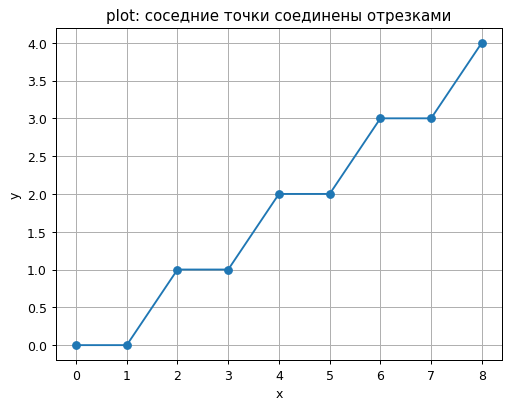

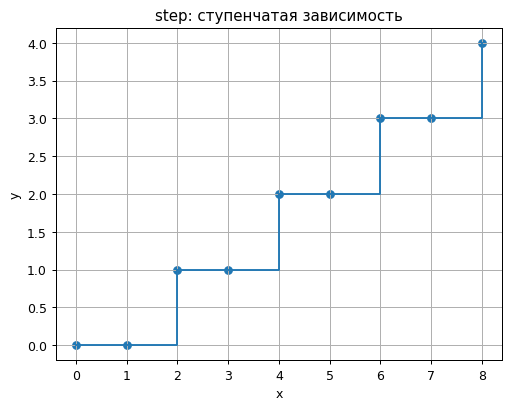

In [5]:
import matplotlib.pyplot as plt

x = list(range(0, 8 + 1))
y = [0, 0, 1, 1, 2, 2, 3, 3, 4]

# plot строит точки по парам элементов одинакового индекса и соединяет соседние точки линиями
plt.plot(x, y, marker='o')
plt.title('plot: соседние точки соединены отрезками')
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True)
plt.show()

# step показывает значение как уровень, постоянный между отсчётами
plt.step(x, y, where='post')
plt.scatter(x, y)
plt.title('step: ступенчатая зависимость')
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True)
plt.show()

# plot линейно интерполирует между точками и скрывает ступенчатый характер данных
# (наклонные отрезки там, где значение на самом деле постоянно, а потом скачком растёт).
# step показывает именно ступени: значение удерживается до следующего отсчёта.

## С5. Оформление и сравнение

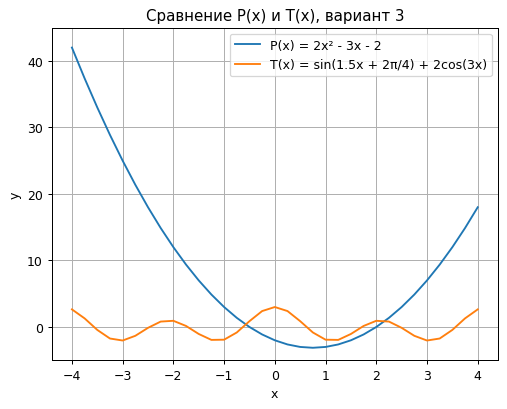

In [6]:
x = np.arange(-4, 4 + 0.25, 0.25)
y_P = 2*x**2 - 3*x - 2
y_T = 1*np.sin(1.5*x + 2*np.pi/4) + 2*np.cos(3*x)

plt.plot(x, y_P, label='P(x) = 2x² - 3x - 2')
plt.plot(x, y_T, label='T(x) = sin(1.5x + 2π/4) + 2cos(3x)')
plt.title('Сравнение P(x) и T(x), вариант 3')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.ylim(-5, 45)
plt.show()

## С6. Числовой и визуальный анализ

    x       y
 -4.00   42.000
 -3.75   37.375
 -3.50   33.000
 -3.25   28.875
 -3.00   25.000
 -2.75   21.375
 -2.50   18.000
 -2.25   14.875
 -2.00   12.000
 -1.75    9.375
 -1.50    7.000
 -1.25    4.875
 -1.00    3.000
 -0.75    1.375
 -0.50    0.000
 -0.25   -1.125
  0.00   -2.000
  0.25   -2.625
  0.50   -3.000
  0.75   -3.125
  1.00   -3.000
  1.25   -2.625
  1.50   -2.000
  1.75   -1.125
  2.00    0.000
  2.25    1.375
  2.50    3.000
  2.75    4.875
  3.00    7.000
  3.25    9.375
  3.50   12.000
  3.75   14.875
  4.00   18.000

min = -3.125  при x = 0.75  (индекс 19 )
max = 42.0  при x = -4.0  (индекс 0 )
sum = 308.0
mean = 9.333333333333334

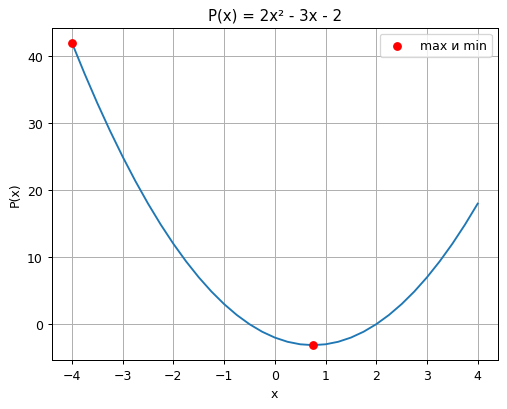

In [7]:
x = np.arange(-4, 4 + 0.25, 0.25)
y = 2*x**2 - 3*x - 2

# таблица значений
print('    x       y')
for i in range(len(x)):
    print(f'{x[i]:6.2f} {y[i]:8.3f}')

i_max = np.argmax(y)
i_min = np.argmin(y)

print()
print('min =', np.min(y), ' при x =', x[i_min], ' (индекс', i_min, ')')
print('max =', np.max(y), ' при x =', x[i_max], ' (индекс', i_max, ')')
print('sum =', np.sum(y))
print('mean =', np.mean(y))

assert len(x) == len(y)
plt.plot(x, y)
plt.scatter([x[i_max], x[i_min]], [y[i_max], y[i_min]], color='red', zorder=3, label='max и min')
plt.title('P(x) = 2x² - 3x - 2')
plt.xlabel('x'); plt.ylabel('P(x)')
plt.grid(True); plt.legend()
plt.show()

## С7. Три семейства функций и масштаб

Для $P(x)$, $R(x)$ и $T(x)$ своего варианта:
1. вычислите массивы на заданной сетке;
2. корректно обработайте точку $x=d$ рациональной функции;
3. постройте три графика;
4. укажите, является ли особая точка $R(x)$ полюсом или устранимым разрывом;
5. отдельно постройте функцию $G(x)$ своего варианта в обычном и логарифмическом масштабе и сравните представления.

In [8]:
# 1. Вычисление массивов
x = np.arange(-4, 4 + 0.25, 0.25)       # сетка для P, R, T (33 точки)
x_G = np.linspace(0, 8, 33)             # сетка для G на [0, 8], шаг 0.25

y_P = 2*x**2 - 3*x - 2
y_T = 1*np.sin(1.5*x + 2*np.pi/4) + 2*np.cos(3*x)
y_G = (x_G + 2)**7

print('G(0) =', y_G[0], ' G(8) =', y_G[-1])
print('min G =', y_G.min(), ' max G =', y_G.max())

G(0) = 128.0  G(8) = 10000000.0
min G = 128.0  max G = 10000000.0

In [9]:
# 2. Рациональная функция: в точке x = d = -1 знаменатель равен нулю -> значение nan
y_R = np.full(x.shape, np.nan, dtype=float)
mask = np.abs(x + 1) > 1e-12
y_R[mask] = (-x[mask] + 3) / (x[mask] + 1)
print(y_R)
print('x = -1 -> y_R =', y_R[np.isclose(x, -1)])

[ -2.33333333  -2.45454545  -2.6         -2.77777778  -3.
  -3.28571429  -3.66666667  -4.2         -5.          -6.33333333
  -9.         -17.                  nan  15.           7.
   4.33333333   3.           2.2          1.66666667   1.28571429
   1.           0.77777778   0.6          0.45454545   0.33333333
   0.23076923   0.14285714   0.06666667   0.          -0.05882353
  -0.11111111  -0.15789474  -0.2       ]
x = -1 -> y_R = [nan]

Числитель при x = -1: 4 -> полюс

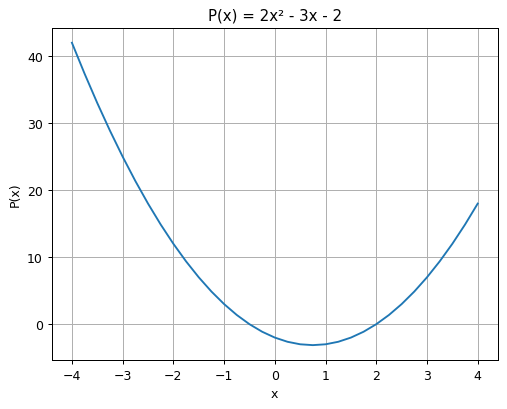

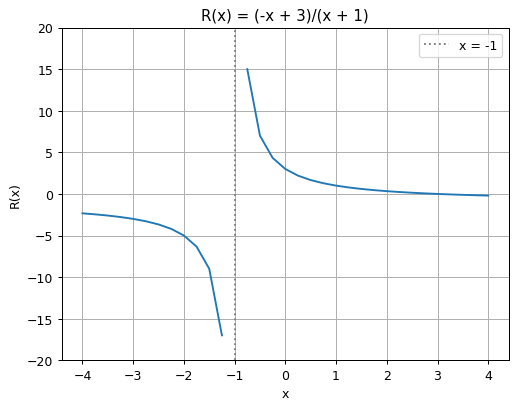

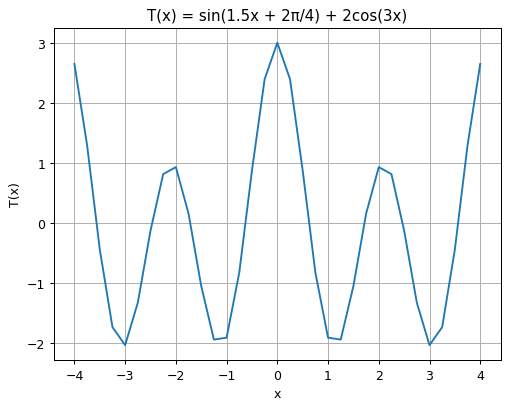

In [10]:
# 3. Три графика (по оси абсцисс — x, а не номер элемента)
plt.plot(x, y_P)
plt.title('P(x) = 2x² - 3x - 2')
plt.xlabel('x'); plt.ylabel('P(x)'); plt.grid(True)
plt.show()

plt.plot(x, y_R)                       # в точке x = -1 стоит nan, линия разрывается
plt.axvline(-1, linestyle=':', color='gray', label='x = -1')
plt.ylim(-20, 20)
plt.title('R(x) = (-x + 3)/(x + 1)')
plt.xlabel('x'); plt.ylabel('R(x)'); plt.grid(True); plt.legend()
plt.show()

plt.plot(x, y_T)
plt.title('T(x) = sin(1.5x + 2π/4) + 2cos(3x)')
plt.xlabel('x'); plt.ylabel('T(x)'); plt.grid(True)
plt.show()

# 4. При x = -1 числитель равен -(-1) + 3 = 4 != 0, общего множителя нет,
#    значит, особая точка — полюс (неустранимый разрыв): |R(x)| -> бесконечность при x -> -1.
print('Числитель при x = -1:', -(-1) + 3, '-> полюс')

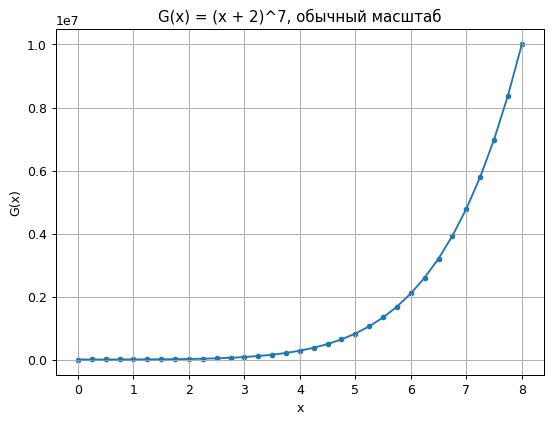

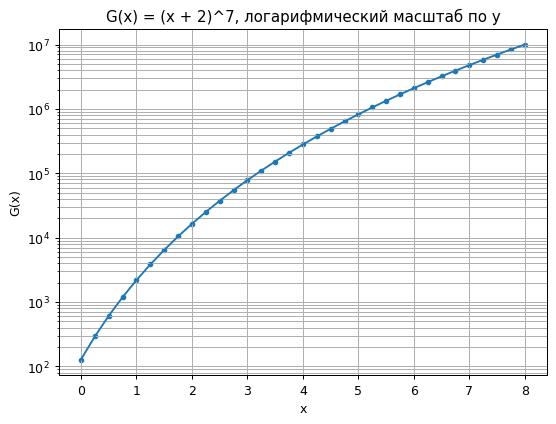

In [11]:
# 5. G(x) = (x + 2)^7 на [0, 8]: обычный и логарифмический масштаб по y
plt.figure(figsize=(7, 5))
plt.plot(x_G, y_G)
plt.scatter(x_G, y_G, s=12)
plt.title('G(x) = (x + 2)^7, обычный масштаб')
plt.xlabel('x'); plt.ylabel('G(x)'); plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(x_G, y_G)
plt.scatter(x_G, y_G, s=12)
plt.yscale('log')
plt.title('G(x) = (x + 2)^7, логарифмический масштаб по y')
plt.xlabel('x'); plt.ylabel('G(x)'); plt.grid(True, which='both')
plt.show()

Сравнение: в обычном масштабе G(x) растёт от 128 до 10⁷, и значения при малых x практически сливаются с осью (график почти плоский, а затем резко уходит вверх). В логарифмическом масштабе по y все значения видны: так как log G = 7·log(x+2), график получается плавным и близким к прямой, и по нему легко сравнивать порядки величин.